![Banner](../../../../Images/Banner/05_geostat/08_bayesian_kriging.png)

# Bayesian Generalized Linear Kriging (`BayesianGLMKriging`)

**Datasets:** 666 counties of the US Atlantic region: lung and bronchus cancer mortality rates with population and covariates (`Data/00_shared/data_geostatistics/lbc_rate.csv`), diabetes prevalence with obesity and physical-inactivity covariates (`diabetes_atlantic.csv`), and the county polygons (`COUNTY_ATLANTIC.shp`)

**Targets:** (1) one year of lung-cancer deaths per county, a Poisson count with expected deaths as exposure; (2) a small diabetes survey per county, a binomial count. Both are **simulated from the real county rates**, so the true surface is known and the estimates can be checked against it.

**Library:** `geolattice.geostatistics.BayesianGLMKriging` (module `geolattice.geostatistics.kriging.bayesian_kriging`)

**Before this notebook:** [Bayesian kriging](05_08_02_bayesian_kriging.ipynb) (Gaussian data) and [Poisson kriging](../05_06_poisson_kriging/05_06_00_poisson_kriging.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [Why raw rates are noisy](#why-raw-rates-are-noisy)
    - 2.2 [The spatial generalized linear mixed model](#the-spatial-generalized-linear-mixed-model)
    - 2.3 [Priors](#priors)
    - 2.4 [The posterior and why it needs MCMC](#the-posterior-and-why-it-needs-mcmc)
    - 2.5 [Whitening the latent field](#whitening-the-latent-field)
    - 2.6 [MALA for the latent field](#mala-for-the-latent-field)
    - 2.7 [The other updates and adaptation](#the-other-updates-and-adaptation)
    - 2.8 [Prediction](#prediction)
    - 2.9 [Convergence diagnostics](#convergence-diagnostics)
    - 2.10 [Relation to Poisson kriging and disease mapping](#relation-to-poisson-kriging-and-disease-mapping)
3. [Python Setup](#python-setup)
4. [Data: Real Rates, Simulated Counts](#data-real-rates-simulated-counts)
5. [Raw Standardized Mortality Ratios](#raw-standardized-mortality-ratios)
6. [Fitting the Poisson Model](#fitting-the-poisson-model)
    - 6.1 [Convergence: traces, acceptance, ESS and R-hat](#convergence-traces-acceptance-ess-and-r-hat)
    - 6.2 [Posterior of the parameters](#posterior-of-the-parameters)
7. [Smoothed Relative Risks](#smoothed-relative-risks)
8. [Prediction at Held-Out Counties](#prediction-at-held-out-counties)
9. [Exceedance Probabilities](#exceedance-probabilities)
10. [The Unstructured (Nugget) Term](#the-unstructured-nugget-term)
11. [How Much Smoothing: the Effect of Exposure](#how-much-smoothing-the-effect-of-exposure)
12. [Binomial Model: Diabetes Prevalence from Small Surveys](#binomial-model-diabetes-prevalence-from-small-surveys)
13. [Summary and Conclusions](#summary-and-conclusions)
    - 13.1 [Practical guidance](#practical-guidance)
14. [References](#references)

***
## Overview

Counts of disease cases, deaths, species occurrences or defects are not Gaussian: they are non-negative integers whose variance depends on their mean. A county with 3 expected deaths that records 7 has a raw rate more than twice the expected one, purely by chance. Raw rates are most extreme where populations are smallest, which is exactly where they are least reliable. Mapping them, or kriging them as if they were Gaussian, gives maps dominated by small-population noise.

**Bayesian generalized linear kriging** (a spatial generalized linear mixed model, GLMM; Diggle, Tawn & Moyeed, 1998) models the counts with their proper distribution, Poisson or binomial. The log rate (or logit probability) is a regression on covariates plus a spatially correlated Gaussian field. The Bayesian fit borrows strength across space: noisy small-population counties are shrunk toward their neighbours and their covariates, while large-population counties keep their own rates. Every estimate comes with a full posterior.

| `BayesianGLMKriging` | |
|---|---|
| `family` | `"poisson"` (log link, exposure / expected counts) or `"binomial"` (logit link, number of trials) |
| model | trend (polynomial in the coordinates plus covariates) + latent Gaussian field with a chosen correlation model and relative nugget |
| fit | MCMC: whitened latent field by MALA, random-walk Metropolis for $\beta$ and $\sigma^2$, the range on a discrete grid, plus centred (interweaving) Gibbs updates |
| outputs | `trace_`, `acceptance_`, `latent_samples()`, `predictive_samples()`, `predict()` (mean, sd, quantiles), `predict_proba()` |

This notebook uses **real county rates as the truth** and **simulated counts as the data**:

* one year of lung-cancer deaths per county, $y_i \sim \text{Poisson}(\text{rate}_i \times \text{population}_i)$;
* a small diabetes survey per county, $y_i \sim \text{Binomial}(n_i, \text{prevalence}_i)$.

Because the true rates are known, the notebook can check how much the model improves on raw rates, whether its credible intervals cover the truth, and how both depend on the size of the counts.

***
## Theory

### Why raw rates are noisy

For a county with expected count $E_i$ under the region-wide rate, and observed count $y_i \sim \text{Poisson}(E_i \theta_i)$, the **standardized mortality ratio** $\text{SMR}_i = y_i / E_i$ is unbiased for the relative risk $\theta_i$, but

$$
\operatorname{Var}(\text{SMR}_i) = \frac{\theta_i}{E_i}.
$$

Its noise is inversely proportional to the expected count. A county with $E_i = 2$ has a standard error of about 0.7 on a relative risk near 1, which is useless, while one with $E_i = 1000$ has 0.03. The map of raw SMRs mostly shows where populations are small.

### The spatial generalized linear mixed model

Conditionally on a latent field, the counts are independent:

$$
y_i \mid \eta_i \sim \begin{cases} \text{Poisson}\bigl(E_i\, e^{\eta_i}\bigr) & \text{(log link; } E_i \text{ = expected count or exposure)} \\ \text{Binomial}\bigl(n_i,\; \text{logit}^{-1}(\eta_i)\bigr) & \text{(logit link; } n_i \text{ = trials)} \end{cases}
$$

The linear predictor is

$$
\boldsymbol\eta = \mathbf{F}\boldsymbol\beta + \mathbf{S},
\qquad
\mathbf{S} \sim \mathcal{N}\bigl(\mathbf{0},\; \sigma^2[\mathbf{R}(\phi) + \tau \mathbf{I}]\bigr),
$$

where:

* $\mathbf{F}$ holds the trend (intercept, optional polynomial in the coordinates) and the covariates;
* $\mathbf{R}(\phi)$ is the spatial correlation with range $\phi$;
* $\tau$ is a relative **nugget**: unstructured, county-specific extra variation (overdispersion) that is not spatially smooth.

With expected counts as exposure, $e^{\eta_i}$ is the relative risk $\theta_i$.

### Priors

$$
\boldsymbol\beta \sim \mathcal{N}(\mathbf{0},\, s_\beta^2 \mathbf{I}),
\qquad
\sigma^2 \sim \text{Scale-inv-}\chi^2(\nu_0, s_0^2),
\qquad
\phi \sim \text{discrete prior on a grid}.
$$

The arguments are `beta_prior_sd` (default 10), `sigma2_prior=(df, scale2)` (default (1, 0.5)), `range_grid` and `range_prior`, and the relative nugget $\tau$ (`nugget_ratio`, fixed). Counts carry much less information about the latent variance than Gaussian data do, binary data least of all, so the $\sigma^2$ prior deserves attention.

### The posterior and why it needs MCMC

The joint posterior is

$$
p(\boldsymbol\beta, \sigma^2, \phi, \mathbf{S} \mid \mathbf{y}) \propto \prod_i p(y_i \mid \eta_i)\; \mathcal{N}(\mathbf{S} \mid \mathbf{0}, \sigma^2\mathbf{V}(\phi))\; p(\boldsymbol\beta)\, p(\sigma^2)\, p(\phi).
$$

Because the Poisson and binomial likelihoods are not Gaussian in $\boldsymbol\eta$, nothing integrates in closed form (unlike Gaussian Bayesian kriging), so the posterior is sampled by Markov chain Monte Carlo.

### Whitening the latent field

Sampling $\mathbf{S}$ directly mixes badly: its components are strongly correlated, and its scale changes with $\sigma^2$ and $\phi$. Following Christensen (2004), GeoLattice writes

$$
\mathbf{S} = \sigma \mathbf{L}(\phi)\boldsymbol\Gamma,
\qquad \mathbf{L}\mathbf{L}^\top = \mathbf{R}(\phi) + \tau\mathbf{I},
\qquad \boldsymbol\Gamma \sim \mathcal{N}(\mathbf{0}, \mathbf{I}),
$$

so the prior of $\boldsymbol\Gamma$ is white noise whatever $\sigma^2$ and $\phi$ are. The Cholesky factors $\mathbf{L}(\phi)$ are computed once for every range on the grid.

### MALA for the latent field

$\boldsymbol\Gamma$ is updated by the **Metropolis-adjusted Langevin algorithm**, a random walk that drifts along the gradient of the log posterior:

$$
\boldsymbol\Gamma' = \boldsymbol\Gamma + \frac{h}{2}\nabla(\boldsymbol\Gamma) + \sqrt{h}\,\boldsymbol\epsilon,
\qquad
\nabla(\boldsymbol\Gamma) = \sigma\mathbf{L}^\top\bigl(\mathbf{y} - E[\mathbf{y} \mid \boldsymbol\eta]\bigr) - \boldsymbol\Gamma,
$$

with $E[y_i \mid \eta_i] = E_i e^{\eta_i}$ (Poisson) or $n_i\,\text{logit}^{-1}(\eta_i)$ (binomial). The proposal is accepted with probability $\min(1, \alpha)$, where

$$
\log\alpha = \log p(\boldsymbol\Gamma' \mid \cdot) - \log p(\boldsymbol\Gamma \mid \cdot) - \frac{\lVert\boldsymbol\Gamma - \boldsymbol\Gamma' - \tfrac{h}{2}\nabla(\boldsymbol\Gamma')\rVert^2 - \lVert\boldsymbol\Gamma' - \boldsymbol\Gamma - \tfrac{h}{2}\nabla(\boldsymbol\Gamma)\rVert^2}{2h}.
$$

The gradient lets all $n$ components move at once in a sensible direction. The optimal acceptance rate for MALA is about 0.574 (Roberts & Rosenthal, 1998).

### The other updates and adaptation

* **$\boldsymbol\beta$:** random-walk Metropolis with proposal $\boldsymbol\beta' = \boldsymbol\beta + s_\beta\,\mathbf{C}\boldsymbol\epsilon$, where $\mathbf{C}\mathbf{C}^\top = (\mathbf{F}^\top\mathbf{F})^{-1}$ shapes the proposal to the covariates.
* **$\log\sigma^2$:** random-walk Metropolis, including the Jacobian of the log transform.
* **$\phi$:** a move to a neighbouring value of its grid, accepted by the Metropolis rule. Because of the whitening, changing $\sigma^2$ or $\phi$ changes $\mathbf{S}$ but not $\boldsymbol\Gamma$, which keeps these moves cheap and well mixed.
* **Adaptation:** during burn-in, every 50 iterations the MALA step $h$ and the two random-walk scales are tuned toward their target acceptance rates (0.574, 0.30, 0.30). After burn-in they are frozen, so the kept chain is a valid Markov chain.
* **Interweaving** (`interweave=True`, the default). The whitened parametrization mixes the latent field well, but the intercept, $\sigma^2$ and the range trade off against $\boldsymbol\Gamma$ and move slowly. Each iteration therefore also updates them in the **centred** parametrization, holding the linear predictor $\boldsymbol\eta$ (and so the likelihood) fixed: ancillarity-sufficiency interweaving (Yu & Meng, 2011). Three conditionals are available in closed form:
    * $\boldsymbol\beta \mid \boldsymbol\eta$ is Gaussian;
    * every `range_gibbs_every` iterations, the range is drawn from its exact discrete posterior given $\mathbf{S} = \boldsymbol\eta - \mathbf{F}\boldsymbol\beta$, with $\sigma^2$ integrated out,
    $$
    p(\phi_j \mid \mathbf{S}) \propto p(\phi_j)\,|\mathbf{V}_j|^{-1/2}\,\bigl(\nu_0 s_0^2 + \mathbf{S}^\top\mathbf{V}_j^{-1}\mathbf{S}\bigr)^{-(\nu_0 + n)/2},
    $$
    a collapsed move along the $\sigma^2$-range ridge;
    * $\sigma^2 \mid \mathbf{S}, \phi$ is scaled inverse-$\chi^2$ with $\nu_0 + n$ degrees of freedom.

  Then $\boldsymbol\Gamma$ is reset to $\mathbf{L}^{-1}\mathbf{S}/\sigma$.

### Prediction

For each kept sample $(\boldsymbol\beta, \sigma^2, \phi, \boldsymbol\Gamma)$, the latent field at a new location $\mathbf{x}_0$ is drawn from its kriging distribution given the latent field at the data:

$$
S_0 \mid \mathbf{S} \sim \mathcal{N}\bigl(\sigma\,\mathbf{r}_0^\top\mathbf{L}^{-\top}\boldsymbol\Gamma,\;\; \sigma^2(1 + \tau - \lVert\mathbf{L}^{-1}\mathbf{r}_0\rVert^2)\bigr),
$$

and $\eta_0 = \mathbf{f}_0^\top\boldsymbol\beta + S_0$ is turned into the rate $e^{\eta_0}$ or the probability $\text{logit}^{-1}(\eta_0)$. The draws over samples form the posterior predictive distribution of the rate at $\mathbf{x}_0$. `predict` summarizes them; `predict_proba` gives exceedance probabilities.

### Convergence diagnostics

* **Trace plots** should look like stationary noise.
* **Acceptance rates** (`acceptance_`) should be near their targets.
* **Effective sample size**, $\text{ESS} = N / (1 + 2\sum_k \hat\rho_k)$ with $\hat\rho_k$ the chain's autocorrelations, measures how many independent draws the chain is worth.
* **Several chains** from different seeds should agree. The potential scale reduction $\hat R$ (Gelman & Rubin, 1992) compares between- and within-chain variance; values near 1 (below about 1.05) indicate convergence.

### Relation to Poisson kriging and disease mapping

* **[Poisson kriging](../05_06_poisson_kriging/05_06_00_poisson_kriging.ipynb)** (Monestiez et al., 2006; Goovaerts, 2005) adjusts the kriging system for Poisson noise, but stays a linear, second-order method with a plug-in variogram.
* **The GLMM** uses the full likelihood and propagates every parameter's uncertainty.
* **Disease-mapping models** such as BYM (Besag, York & Mollié, 1991) use areal neighbourhoods and a conditional autoregressive field. The GLMM here treats each county as a point, its centroid, with a geostatistical correlation, and its nugget plays the role of BYM's unstructured term.

***
## Python Setup

`BayesianGLMKriging` runs on the CPU (NumPy). Each MCMC iteration costs a few $n \times n$ matrix-vector products; the Cholesky factors are computed once per range value.

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import BayesianGLMKriging

print("pygstat version:", pygstat.__version__)

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")


def ess(x):
    # effective sample size from the autocorrelation (initial positive sequence)
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    if np.var(x) == 0:
        return float(n)
    ac = np.correlate(x, x, "full")[n - 1:] / (np.var(x) * n)
    s = 0.0
    for k in range(1, n // 2):
        if ac[k] + ac[k + 1] < 0:
            break
        s += ac[k]
    return n / (1 + 2 * s)


def rhat(chains):
    # Gelman-Rubin potential scale reduction for a list of equal-length chains
    c = np.asarray(chains, float)
    m, n = c.shape
    B = n * c.mean(1).var(ddof=1)
    W = c.var(1, ddof=1).mean()
    return float(np.sqrt(((n - 1) / n * W + B / n) / W))

pygstat version: 0.3.44


***
## Data: Real Rates, Simulated Counts

`lbc_rate.csv` gives, for 666 Atlantic-region counties, the lung and bronchus cancer mortality rate per 100,000 (averaged over 1998-2012), the population, county-centroid coordinates (Albers equal-area, metres) and covariates: adult smoking prevalence and poverty. These real rates are treated as the **true rates**.

One year of deaths is simulated from them,

$$
y_i \sim \text{Poisson}(\lambda_i), \qquad \lambda_i = \text{rate}_i \times \text{population}_i / 10^5 .
$$

The expected counts under the region-wide rate are $E_i = \text{population}_i \times \sum_j y_j / \sum_j \text{population}_j$, so the **true relative risk** is $\theta_i = \lambda_i / E_i$. 130 counties are held out at random: their counts are not used for fitting, and the model predicts their relative risk from location and covariates.

In [2]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
lbc = pd.read_csv(DATA + "lbc_rate.csv")
dia = pd.read_csv(DATA + "diabetes_atlantic.csv")
df = lbc.merge(dia[["FIPS", "State", "County", "Diabetes_per", "Obesity", "Physical_Inactivity"]], on="FIPS")
counties = gpd.read_file(DATA + "COUNTY_ATLANTIC.shp")[["FIPS", "geometry"]]
counties["FIPS"] = counties["FIPS"].astype(int)
xy = df[["x", "y"]].to_numpy(float) / 1000.0            # km
n = len(df)

rng = np.random.default_rng(2026)
lam = (df["lbc_rate"] * df["pop"] / 1e5).to_numpy()
y = rng.poisson(lam)
E = df["pop"].to_numpy() * y.sum() / df["pop"].sum()
true_rr = lam / E
smr = y / E

zs = lambda c: ((c - c.mean()) / c.std()).to_numpy()
X = np.column_stack([zs(df.smoking), zs(df.poverty)])
perm = rng.permutation(n)
te, tr = np.sort(perm[:130]), np.sort(perm[130:])
print(f"{n} counties ({len(tr)} for fitting, {len(te)} held out); {y.sum():,} simulated deaths")
print("expected deaths E_i: quantiles 5/25/50/75/95% =", np.round(np.quantile(E, [0.05, 0.25, 0.5, 0.75, 0.95]), 1))
print(f"true relative risk: range {true_rr.min():.2f}-{true_rr.max():.2f}, sd {true_rr.std():.3f}")


def choropleth(ax, values, title, cmap="RdBu_r", vmin=None, vmax=None, label=""):
    g = counties.merge(pd.DataFrame({"FIPS": df.FIPS, "v": values}), on="FIPS", how="left")
    g.plot(column="v", ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, legend=True, linewidth=0.05, edgecolor="0.5",
           legend_kwds={"label": label, "shrink": 0.7}, missing_kwds={"color": "lightgrey"})
    ax.set_title(title)
    ax.set_axis_off()

666 counties (536 for fitting, 130 held out); 53,505 simulated deaths
expected deaths E_i: quantiles 5/25/50/75/95% = [  6.9  15.6  33.3  76.7 324.4]
true relative risk: range 0.57-1.74, sd 0.174


***
## Raw Standardized Mortality Ratios

The raw SMR map against the true relative risk, and the SMR error as a function of the expected count: the funnel of Section 2.1.

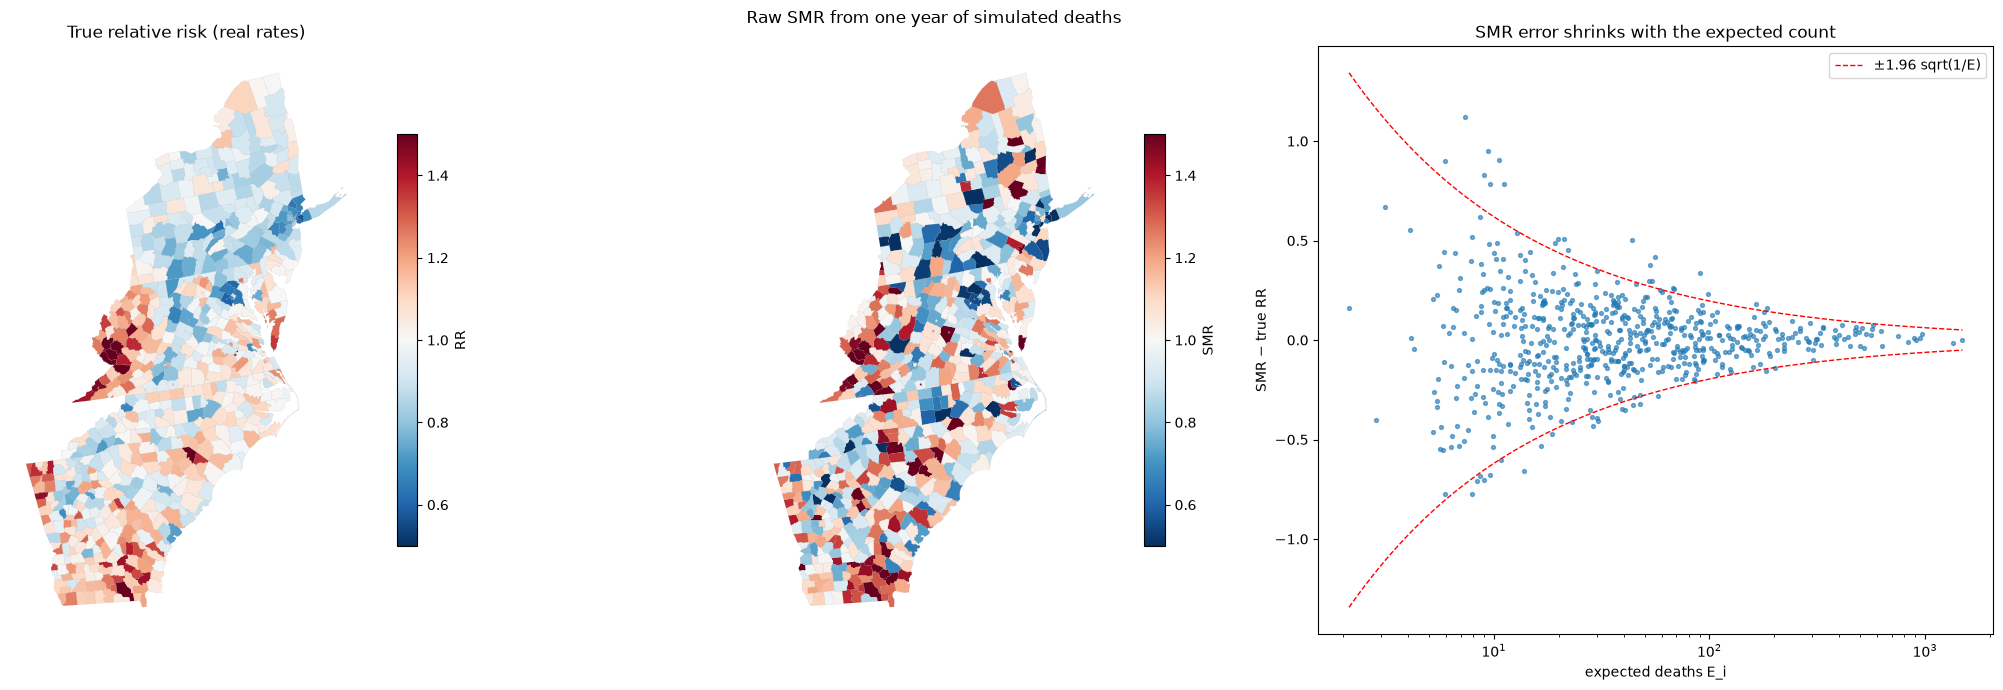

raw SMR: RMSE vs true RR 0.227; counties with E < 10: 12%, their RMSE 0.430


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
choropleth(axes[0], true_rr, "True relative risk (real rates)", vmin=0.5, vmax=1.5, label="RR")
choropleth(axes[1], smr, "Raw SMR from one year of simulated deaths", vmin=0.5, vmax=1.5, label="SMR")
axes[2].scatter(E, smr - true_rr, s=8, alpha=0.6)
ee = np.geomspace(E.min(), E.max(), 100)
axes[2].plot(ee, 1.96 / np.sqrt(ee), "r--", lw=1, label="±1.96 sqrt(1/E)")
axes[2].plot(ee, -1.96 / np.sqrt(ee), "r--", lw=1)
axes[2].set_xscale("log")
axes[2].set_xlabel("expected deaths E_i")
axes[2].set_ylabel("SMR − true RR")
axes[2].set_title("SMR error shrinks with the expected count")
axes[2].legend()
plt.tight_layout()
plt.show()
print(f"raw SMR: RMSE vs true RR {np.sqrt(np.mean((smr - true_rr) ** 2)):.3f}; "
      f"counties with E < 10: {np.mean(E < 10):.0%}, their RMSE {np.sqrt(np.mean((smr - true_rr)[E < 10] ** 2)):.3f}")

***
## Fitting the Poisson Model

* **Data and covariates:** the 536 fitting counties' deaths, their expected counts as exposure, and smoking and poverty, standardized, as covariates.
* **Spatial model:** exponential correlation, with the range on 20 values from 20 to 800 km.
* **Priors:** the default priors, $\beta \sim \mathcal{N}(0, 10^2)$ and $\sigma^2 \sim \text{Scale-inv-}\chi^2(1, 0.5)$.
* **Chain:** 10,000 iterations, 3,000 of burn-in, every 5th kept.

In [4]:
RANGE_GRID = np.geomspace(20, 800, 20)
POIS_KW = dict(family="poisson", model="exponential", range_grid=RANGE_GRID)
FIT_KW = dict(n_iter=10000, burn=3000, thin=5)
t0 = time.perf_counter()
pois = BayesianGLMKriging(**POIS_KW).fit(xy[tr], y[tr], trials_or_exposure=E[tr], covariates=X[tr], seed=0, **FIT_KW)
print(f"MCMC: {FIT_KW['n_iter']:,} iterations on {len(tr)} counties in {time.perf_counter() - t0:.1f} s; "
      f"{len(pois.trace_)} kept samples")
print("acceptance rates:", {k: round(float(v), 2) for k, v in pois.acceptance_.items()})

MCMC: 10,000 iterations on 536 counties in 12.6 s; 1400 kept samples
acceptance rates: {'gamma': 0.82, 'beta': 0.27, 'sigma2': 0.37, 'range': 0.15}


### Convergence: traces, acceptance, ESS and R-hat

The traces of the main parameters, their effective sample sizes, and $\hat R$ from three chains started with different seeds.

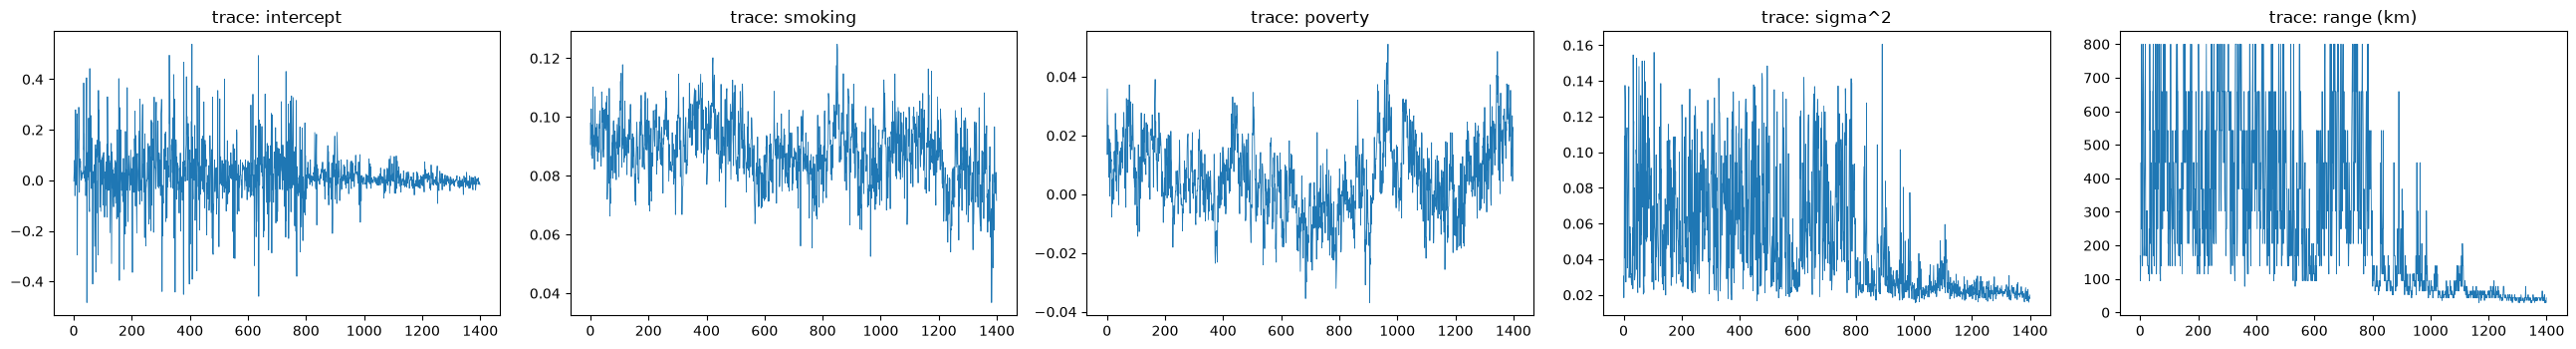

,ESS (chain 1),R-hat (3 chains)
intercept,1400.00,1.00
smoking,48.03,1.02
poverty,24.20,1.00
sigma^2,8.09,1.03
range (km),5.90,1.06


✅ [PASS] R-hat < 1.1 for the regression coefficients  max 1.018


In [5]:
names = {"beta_intercept": "intercept", "beta_cov1": "smoking", "beta_cov2": "poverty", "sigma2": "sigma^2", "range": "range (km)"}
fig, axes = plt.subplots(1, 5, figsize=(26, 3.6))
for ax, (col, lab) in zip(axes, names.items()):
    ax.plot(pois.trace_[col].to_numpy(), lw=0.6)
    ax.set_title(f"trace: {lab}")
plt.tight_layout()
plt.show()

chains = [pois] + [BayesianGLMKriging(**POIS_KW).fit(xy[tr], y[tr], trials_or_exposure=E[tr], covariates=X[tr],
                                                   seed=s, **FIT_KW) for s in (1, 2)]
diag = pd.DataFrame({lab: {"ESS (chain 1)": ess(pois.trace_[col]),
                           "R-hat (3 chains)": rhat([c.trace_[col].to_numpy() for c in chains])}
                     for col, lab in names.items()}).T
display(diag.round(2))
record("R-hat < 1.1 for the regression coefficients",
       "PASS" if diag.loc[["intercept", "smoking", "poverty"], "R-hat (3 chains)"].max() < 1.1 else "FAIL",
       f"max {diag.loc[['intercept', 'smoking', 'poverty'], 'R-hat (3 chains)'].max():.3f}")

* **The regression coefficients converge well.** Thanks to the interweaving updates, the intercept's draws are nearly independent (ESS ≈ 1,400 of 1,400). The smoking and poverty coefficients have ESS of 25-50, and $\hat R \le 1.02$ across three chains.
* **The variance and the range mix slowly.** $\sigma^2$ and the range have $\hat R$ of 1.03-1.06 but ESS below 10: their traces wander. They are weakly identified by counts (only their combination is well determined), and they depend on the slowly moving latent field. Their posterior summaries below are therefore approximate. For precise statements about $\sigma^2$ or the range, run much longer chains (or pool many chains). The relative risks themselves depend mainly on $\boldsymbol\eta$, which the data pin down.
* **Acceptance rates.** The random-walk updates sit near their targets. The MALA acceptance is high (0.82): after burn-in the step size is conservative, which slows the latent field but keeps the chain valid.

### Posterior of the parameters

The kept draws from the three chains are pooled. The coefficients are on the log relative-risk scale per standard deviation of the covariate, so $e^\beta$ is a rate ratio.

,mean,sd,5%,95%,exp(mean)
intercept,0.014,0.093,-0.102,0.164,NaN
smoking,0.090,0.013,0.069,0.111,1.094
poverty,0.004,0.013,-0.017,0.026,1.004
sigma^2,0.042,0.031,0.019,0.115,NaN
range (km),198.453,201.631,43.482,658.826,NaN


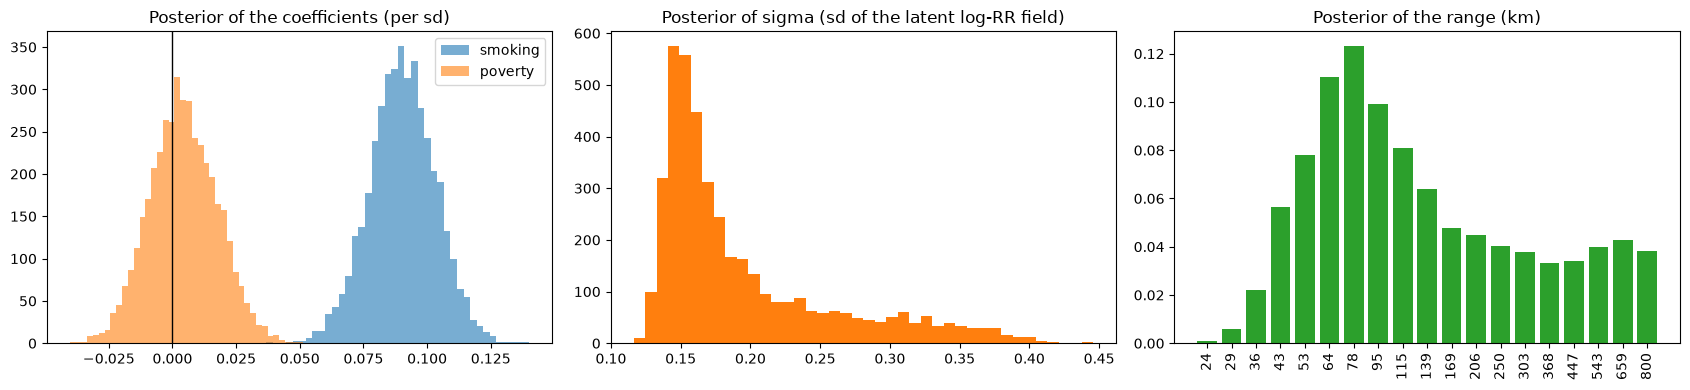

In [6]:
pooled = pd.concat([c.trace_ for c in chains], ignore_index=True)
summ = pd.DataFrame({lab: {"mean": pooled[col].mean(), "sd": pooled[col].std(), "5%": pooled[col].quantile(0.05),
                           "95%": pooled[col].quantile(0.95)} for col, lab in names.items()}).T
summ["exp(mean)"] = np.where(summ.index.isin(["smoking", "poverty"]), np.exp(summ["mean"]), np.nan)
display(summ.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(pooled["beta_cov1"], bins=40, alpha=0.6, label="smoking")
axes[0].hist(pooled["beta_cov2"], bins=40, alpha=0.6, label="poverty")
axes[0].axvline(0, color="k", lw=1)
axes[0].set_title("Posterior of the coefficients (per sd)")
axes[0].legend()
axes[1].hist(np.sqrt(pooled["sigma2"]), bins=40, color="tab:orange")
axes[1].set_title("Posterior of sigma (sd of the latent log-RR field)")
rv = pooled["range"].value_counts(normalize=True).sort_index()
axes[2].bar(np.arange(len(rv)), rv.values, color="tab:green")
axes[2].set_xticks(np.arange(len(rv)), [f"{v:.0f}" for v in rv.index], rotation=90)
axes[2].set_title("Posterior of the range (km)")
plt.tight_layout()
plt.show()

* **Smoking matters.** Its coefficient is clearly positive: +0.090 per standard deviation of smoking prevalence, a rate ratio of 1.09 (90% interval 1.07-1.12).
* **Poverty does not, once smoking and space are accounted for.** Its coefficient is near 0 (0.004, interval −0.017 to 0.026).
* **The residual spatial field is modest.** Its sd is $\sigma \approx 0.2$ on the log relative-risk scale ($\sigma^2$ 0.042, interval 0.019-0.115), so about ±20% residual variation in risk.
* **The range is poorly determined:** posterior mean about 200 km, interval 43-660 km. This is the variance-range ridge discussed above.

***
## Smoothed Relative Risks

The posterior of the relative risk at the fitting counties, $\theta_i = e^{\eta_i}$, comes from `latent_samples()`. It is compared with the truth and the raw SMR, county by county:

* the error of the posterior mean;
* the coverage of the 90% credible intervals;
* the shrinkage of each county's estimate toward the model, as a function of its expected count.

,raw SMR,posterior mean
RMSE vs true RR (all),0.223,0.097
RMSE vs true RR (E < 10),0.425,0.130
coverage of 90% credible intervals,NaN,0.838


✅ [PASS] posterior mean beats raw SMR (RMSE vs truth)  0.223 -> 0.097
✅ [PASS] 90% credible intervals cover the true RR in [0.80, 0.98]  0.84


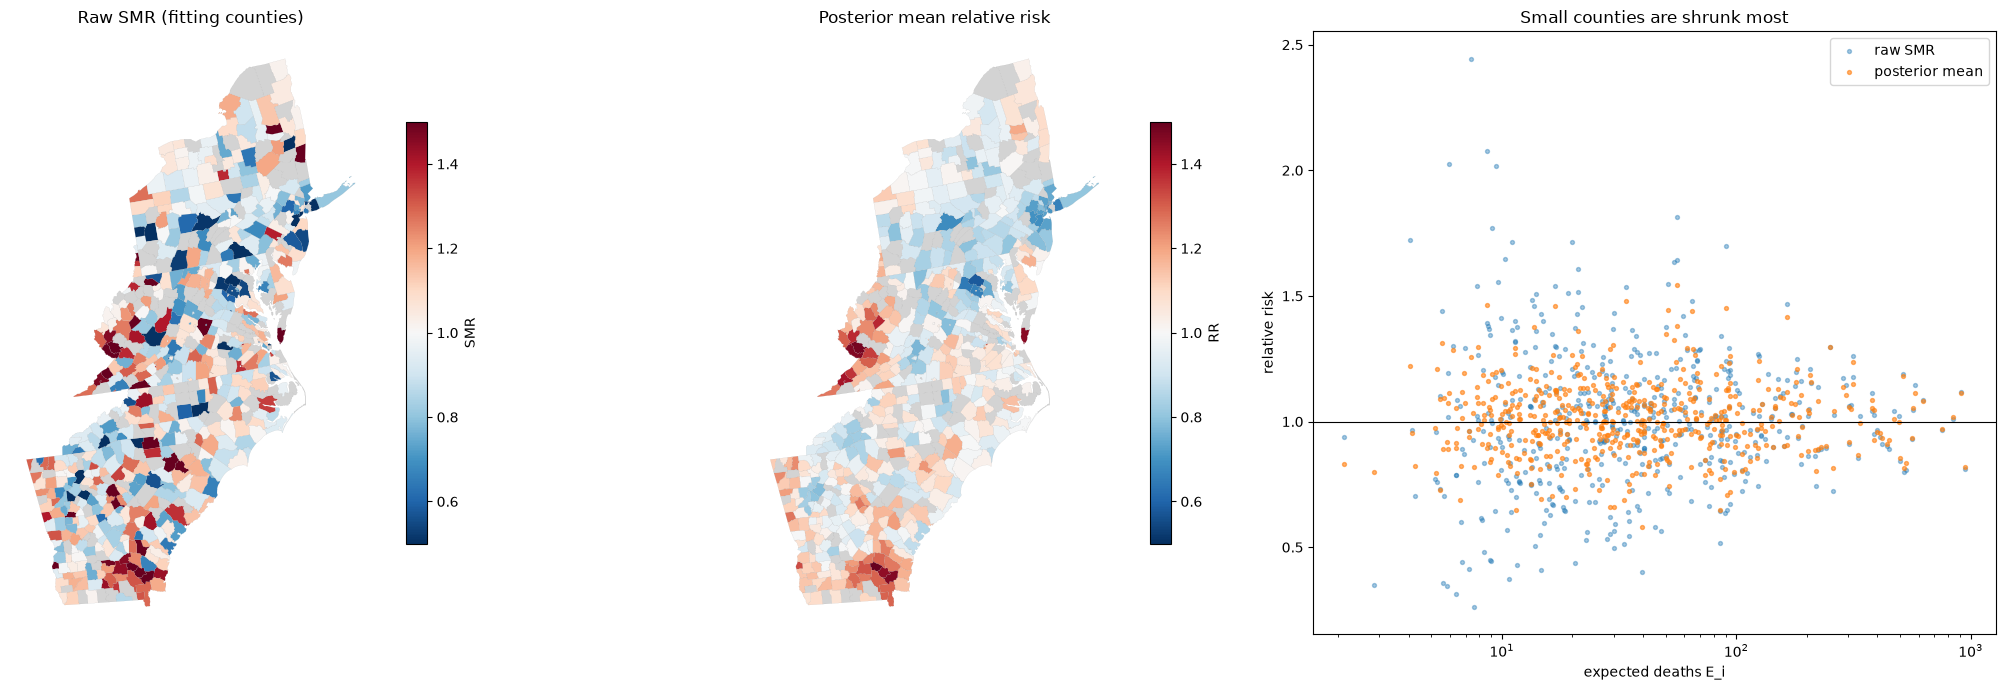

In [7]:
theta = np.exp(np.vstack([c.latent_samples() for c in chains]))       # (draws, fitting counties)
post_mean = theta.mean(0)
lo, hi = np.quantile(theta, [0.05, 0.95], axis=0)
t_tr, smr_tr, E_tr = true_rr[tr], smr[tr], E[tr]
small = E_tr < 10
fit_tab = pd.DataFrame({
    "raw SMR": [np.sqrt(np.mean((smr_tr - t_tr) ** 2)), np.sqrt(np.mean((smr_tr - t_tr)[small] ** 2)), np.nan],
    "posterior mean": [np.sqrt(np.mean((post_mean - t_tr) ** 2)), np.sqrt(np.mean((post_mean - t_tr)[small] ** 2)),
                       np.mean((t_tr >= lo) & (t_tr <= hi))]},
    index=["RMSE vs true RR (all)", "RMSE vs true RR (E < 10)", "coverage of 90% credible intervals"])
display(fit_tab.round(3))
record("posterior mean beats raw SMR (RMSE vs truth)", "PASS" if fit_tab.iloc[0, 1] < fit_tab.iloc[0, 0] else "FAIL",
       f"{fit_tab.iloc[0, 0]:.3f} -> {fit_tab.iloc[0, 1]:.3f}")
record("90% credible intervals cover the true RR in [0.80, 0.98]",
       "PASS" if 0.80 <= fit_tab.iloc[2, 1] <= 0.98 else "FAIL", f"{fit_tab.iloc[2, 1]:.2f}")

all_post = np.full(n, np.nan)
all_post[tr] = post_mean
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
choropleth(axes[0], np.where(np.isin(np.arange(n), tr), smr, np.nan), "Raw SMR (fitting counties)", vmin=0.5, vmax=1.5, label="SMR")
choropleth(axes[1], all_post, "Posterior mean relative risk", vmin=0.5, vmax=1.5, label="RR")
shrink = (smr_tr - post_mean) / np.where(np.abs(smr_tr - 1) > 1e-9, smr_tr - 1, np.nan)
axes[2].scatter(E_tr, smr_tr, s=8, alpha=0.4, label="raw SMR")
axes[2].scatter(E_tr, post_mean, s=8, alpha=0.6, label="posterior mean")
axes[2].set_xscale("log")
axes[2].axhline(1, color="k", lw=0.8)
axes[2].set_xlabel("expected deaths E_i")
axes[2].set_ylabel("relative risk")
axes[2].set_title("Small counties are shrunk most")
axes[2].legend()
plt.tight_layout()
plt.show()

* **The posterior mean is much closer to the truth than the raw SMR.** RMSE falls from 0.223 to 0.097 over all fitting counties, and from 0.425 to 0.130 for the counties with fewer than 10 expected deaths.
* **Shrinkage depends on the expected count.** Small counties are pulled strongly toward their neighbours and covariates; large counties keep their SMR. That is what the scatter plot shows.
* **The map of posterior means looks like the true map.** The raw-SMR map is dominated by speckle from small populations.
* **Coverage.** The 90% credible intervals cover the true relative risk in 84% of counties, slightly below nominal. The slowly mixing variance and range likely make the intervals a little too narrow; longer chains would help.

***
## Prediction at Held-Out Counties

For the 130 held-out counties, no counts are used at all. `predict` draws their relative risk from the covariates and the kriged latent field (Section 2.8). Two baselines:

* **non-spatial Poisson regression** on the same covariates, fitted by iteratively reweighted least squares (IRLS);
* **the regional rate**, $\theta = 1$.

,regional rate (RR = 1),non-spatial Poisson GLM,BayesianGLMKriging
RMSE vs true RR,0.176,0.131,0.107
coverage of 90% intervals,NaN,NaN,0.885


✅ [PASS] spatial GLMM beats non-spatial GLM at held-out counties  0.131 -> 0.107


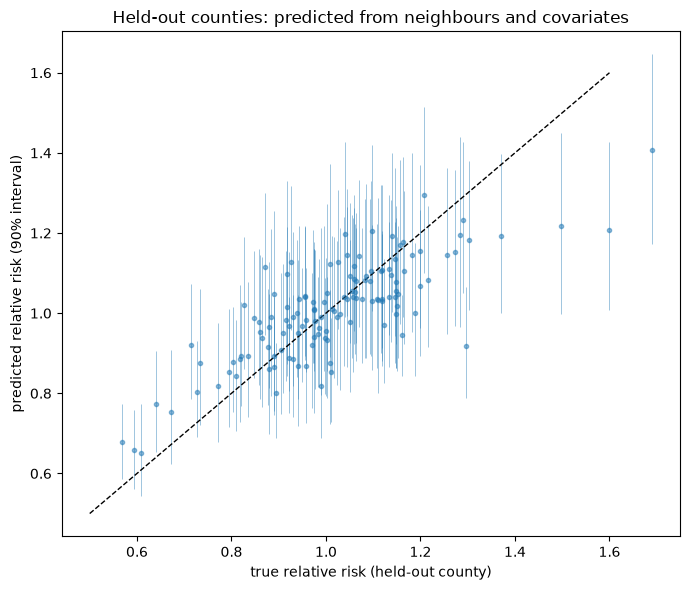

In [8]:
pred_te = pd.concat([c.predict(xy[te], covariates=X[te], seed=i) for i, c in enumerate(chains)])
pred_samples = np.vstack([c.predictive_samples(xy[te], covariates=X[te], seed=10 + i) for i, c in enumerate(chains)])
p_mean = pred_samples.mean(0)
p_lo, p_hi = np.quantile(pred_samples, [0.05, 0.95], axis=0)

# non-spatial Poisson GLM (IRLS) on the fitting counties
F = np.column_stack([np.ones(len(tr)), X[tr]])
b = np.zeros(F.shape[1])
for _ in range(50):
    mu = E[tr] * np.exp(F @ b)
    W = mu
    zwork = F @ b + (y[tr] - mu) / mu
    b = np.linalg.solve(F.T @ (W[:, None] * F), F.T @ (W * zwork))
glm_rr = np.exp(np.column_stack([np.ones(len(te)), X[te]]) @ b)

t_te = true_rr[te]
held = pd.DataFrame({
    "regional rate (RR = 1)": [np.sqrt(np.mean((1 - t_te) ** 2)), np.nan],
    "non-spatial Poisson GLM": [np.sqrt(np.mean((glm_rr - t_te) ** 2)), np.nan],
    "BayesianGLMKriging": [np.sqrt(np.mean((p_mean - t_te) ** 2)), np.mean((t_te >= p_lo) & (t_te <= p_hi))]},
    index=["RMSE vs true RR", "coverage of 90% intervals"])
display(held.round(3))
record("spatial GLMM beats non-spatial GLM at held-out counties",
       "PASS" if held.loc["RMSE vs true RR", "BayesianGLMKriging"] < held.loc["RMSE vs true RR", "non-spatial Poisson GLM"] else "FAIL",
       f"{held.loc['RMSE vs true RR', 'non-spatial Poisson GLM']:.3f} -> {held.loc['RMSE vs true RR', 'BayesianGLMKriging']:.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.errorbar(t_te, p_mean, yerr=[p_mean - p_lo, p_hi - p_mean], fmt="o", ms=3, alpha=0.5, lw=0.6)
ax.plot([0.5, 1.6], [0.5, 1.6], "k--", lw=1)
ax.set_xlabel("true relative risk (held-out county)")
ax.set_ylabel("predicted relative risk (90% interval)")
ax.set_title("Held-out counties: predicted from neighbours and covariates")
plt.tight_layout()
plt.show()

For counties with no data at all, the spatial model predicts the true relative risk with RMSE 0.107:

* better than the non-spatial Poisson regression on the same covariates (0.131);
* much better than assuming the regional rate (0.176).

The difference over the non-spatial model is what the latent field contributes: residual risk shared with neighbouring counties that smoking does not explain. The 90% predictive intervals cover 89% of the held-out true risks.

***
## Exceedance Probabilities

Public-health questions are often "where is the risk clearly elevated?" From the posterior draws, $P(\theta_i > 1.2 \mid \mathbf{y})$ for every county: fitted counties from their latent samples, held-out counties from their predictive samples. A common rule flags counties with probability above 0.8.

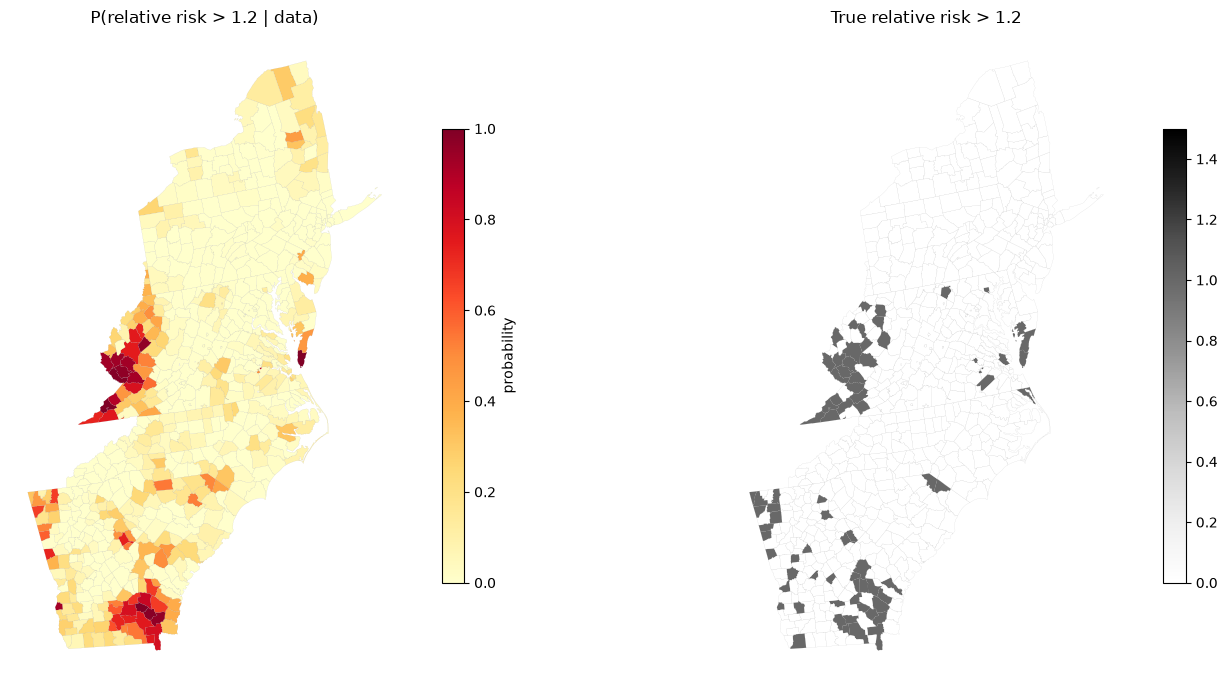

,flag P > 0.8 (model),flag SMR > 1.2 (raw)
correctly flagged,17,49
false alarms,1,84
missed,62,30


In [9]:
p_exceed = np.full(n, np.nan)
p_exceed[tr] = (theta > 1.2).mean(0)
p_exceed[te] = (pred_samples > 1.2).mean(0)
flag = p_exceed > 0.8
truly_high = true_rr > 1.2
smr_flag = smr > 1.2
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
choropleth(axes[0], p_exceed, "P(relative risk > 1.2 | data)", cmap="YlOrRd", vmin=0, vmax=1, label="probability")
choropleth(axes[1], truly_high.astype(float), "True relative risk > 1.2", cmap="Greys", vmin=0, vmax=1.5, label="")
plt.tight_layout()
plt.show()
conf = pd.DataFrame({
    "flag P > 0.8 (model)": [np.sum(flag & truly_high), np.sum(flag & ~truly_high), np.sum(~flag & truly_high)],
    "flag SMR > 1.2 (raw)": [np.sum(smr_flag & truly_high), np.sum(smr_flag & ~truly_high), np.sum(~smr_flag & truly_high)]},
    index=["correctly flagged", "false alarms", "missed"])
display(conf)

The two flagging rules behave very differently:

| Rule | Correctly flagged | False alarms | Missed |
|---|---|---|---|
| raw SMR > 1.2 | 49 | 84 | 30 |
| model, P(RR > 1.2) > 0.8 | 17 | 1 | 62 |

* **The raw rule** catches more truly elevated counties, but at the price of 84 false alarms, most of them small counties with a few extra deaths by chance.
* **The model rule** is conservative: it raises one false alarm but misses many truly elevated counties whose risk is only modestly above 1.2.

The probability threshold sets that trade-off explicitly; a lower one, for example 0.5, flags more counties with more false alarms. Either way the probability map says how sure each flag is, which a raw-rate map cannot.

***
## The Unstructured (Nugget) Term

A purely spatial field forces neighbouring counties to have similar risks. Real risks also vary county by county for reasons that are not spatially smooth: local industry, demography, reporting. `nugget_ratio` $\tau$ adds that unstructured variation. The fit is repeated with $\tau$ = 0, 0.2 and 1, and scored against the truth.

In [10]:
rows = []
for tau in [0.0, 0.2, 1.0]:
    m = BayesianGLMKriging(**POIS_KW, nugget_ratio=tau).fit(xy[tr], y[tr], trials_or_exposure=E[tr], covariates=X[tr], seed=0, **FIT_KW)
    th = np.exp(m.latent_samples())
    ps = m.predictive_samples(xy[te], covariates=X[te], seed=1)
    q_lo, q_hi = np.quantile(ps, [0.05, 0.95], axis=0)
    rows.append({"nugget ratio": tau, "posterior mean sigma^2": m.trace_.sigma2.mean(), "posterior mean range": m.trace_.range.mean(),
                 "fit RMSE": np.sqrt(np.mean((th.mean(0) - t_tr) ** 2)),
                 "held-out RMSE": np.sqrt(np.mean((ps.mean(0) - t_te) ** 2)),
                 "held-out 90% coverage": np.mean((t_te >= q_lo) & (t_te <= q_hi)),
                 "MALA acceptance": m.acceptance_["gamma"]})
pd.DataFrame(rows).set_index("nugget ratio").round(3)

,posterior mean sigma^2,posterior mean range,fit RMSE,held-out RMSE,held-out 90% coverage,MALA acceptance
nugget ratio,,,,,,
0.0,0.050,270.806,0.100,0.104,0.885,0.819
0.2,0.042,610.617,0.102,0.106,0.931,0.376
1.0,0.014,461.036,0.099,0.108,0.962,0.679


* **Fit quality.** Point accuracy hardly changes with the nugget: fit RMSE about 0.10 and held-out RMSE 0.104-0.108.
* **Calibration changes.** The held-out 90% intervals cover 89% of true risks without a nugget, 93% with $\tau = 0.2$, and 96% with $\tau = 1$. A nugget adds unstructured variance at unsampled counties, so their predictive intervals widen.
* **Variance split.** As $\tau$ grows, the spatial variance $\sigma^2$ falls (0.050 to 0.014), because part of the variation is reassigned to the unstructured term.

Here the true rates are fairly smooth, so a small nugget is enough. For real disease data, with local factors the covariates miss, an unstructured term is usually essential (as in BYM).

***
## How Much Smoothing: the Effect of Exposure

The benefit of the model depends on how informative the counts are. The same true rates are used to simulate deaths over **three months**, **one year** and **five years** (exposure × 0.25, 1, 5), and the raw SMR and the posterior mean are compared with the truth for each.

In [11]:
rows = []
for scale, label in [(0.25, "3 months"), (1.0, "1 year"), (5.0, "5 years")]:
    ys = np.random.default_rng(int(scale * 100)).poisson(lam * scale)
    Es = df["pop"].to_numpy() * ys.sum() / df["pop"].sum()
    tr_rr = (lam * scale / Es)[tr]
    smr_s = (ys / Es)[tr]
    m = BayesianGLMKriging(**POIS_KW).fit(xy[tr], ys[tr], trials_or_exposure=Es[tr], covariates=X[tr], seed=0, **FIT_KW)
    pm = np.exp(m.latent_samples()).mean(0)
    rows.append({"exposure": label, "median expected deaths": np.median(Es[tr]),
                 "raw SMR RMSE": np.sqrt(np.mean((smr_s - tr_rr) ** 2)), "posterior mean RMSE": np.sqrt(np.mean((pm - tr_rr) ** 2)),
                 "posterior mean sigma^2": m.trace_.sigma2.mean()})
expo = pd.DataFrame(rows).set_index("exposure")
expo["RMSE reduction"] = 1 - expo["posterior mean RMSE"] / expo["raw SMR RMSE"]
expo.round(3)

,median expected deaths,raw SMR RMSE,posterior mean RMSE,posterior mean sigma^2,RMSE reduction
exposure,,,,,
3 months,8.306,0.428,0.107,0.057,0.750
1 year,33.245,0.205,0.093,0.044,0.546
5 years,165.158,0.093,0.080,0.055,0.140


The less informative the counts, the more the model helps:

| Exposure | Median expected deaths | Raw SMR RMSE | Model RMSE | Reduction |
|---|---|---|---|---|
| 3 months | 8 | 0.43 | 0.11 | 75% |
| 1 year | 33 | 0.21 | 0.09 | 55% |
| 5 years | 165 | 0.093 | 0.080 | 14% |

The model's RMSE stays near 0.08-0.11 throughout. With large counts the data speak for themselves and the model only trims residual noise.

***
## Binomial Model: Diabetes Prevalence from Small Surveys

`diabetes_atlantic.csv` gives the diagnosed diabetes prevalence of each county, treated here as the truth. A small survey is simulated in each county, with $n_i$ = 30 respondents and $y_i \sim \text{Binomial}(n_i, \text{prevalence}_i)$. The binomial model (`family="binomial"`, `trials_or_exposure=n_i`) uses obesity and physical inactivity as covariates. Survey proportions with 30 respondents are very noisy: one case moves them by 3.3 percentage points.

binomial MCMC in 15.3 s; acceptance: {'gamma': 0.5, 'beta': 0.25, 'sigma2': 0.29, 'range': 0.54}


,beta_intercept,beta_cov1,beta_cov2,sigma2,range,loglik
mean,-2.278,0.080,0.030,0.101,606.153,-4811.586
std,0.194,0.052,0.049,0.041,198.712,5.467


,survey proportion,BayesianGLMKriging
"RMSE, surveyed counties (pct points)",5.085,0.983
"RMSE, held-out counties (pct points)",NaN,1.148
held-out 90% coverage,NaN,0.931


✅ [PASS] binomial model beats raw survey proportions  5.08 -> 0.98 percentage points


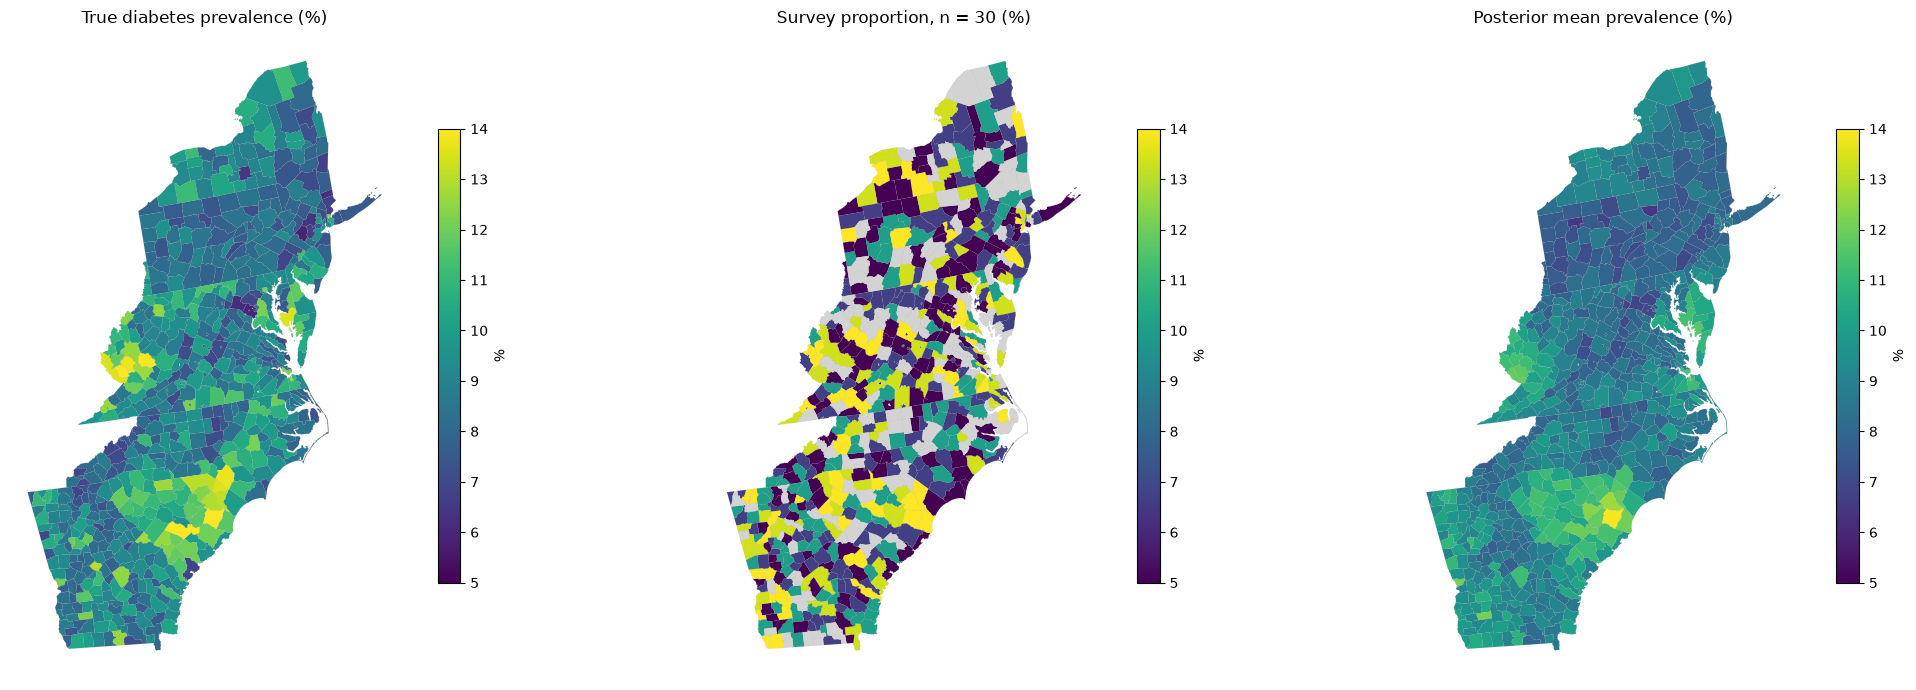

In [12]:
prev = df["Diabetes_per"].to_numpy() / 100
n_i = np.full(n, 30)
yb = np.random.default_rng(7).binomial(n_i, prev)
Xb = np.column_stack([zs(df.Obesity), zs(df.Physical_Inactivity)])
t0 = time.perf_counter()
binm = BayesianGLMKriging("binomial", model="exponential", range_grid=RANGE_GRID,
                          sigma2_prior=(4.0, 0.25), beta_prior_sd=2.5).fit(
    xy[tr], yb[tr], trials_or_exposure=n_i[tr], covariates=Xb[tr], seed=0, n_iter=12000, burn=4000, thin=5)
print(f"binomial MCMC in {time.perf_counter() - t0:.1f} s; acceptance:", {k: round(float(v), 2) for k, v in binm.acceptance_.items()})
display(binm.trace_.describe().loc[["mean", "std"]].round(3))

pb_fit = (1 / (1 + np.exp(-binm.latent_samples()))).mean(0)
pb_te = binm.predict(xy[te], covariates=Xb[te], seed=1)
raw_p = yb / n_i
pv_tr, pv_te = prev[tr], prev[te]
btab = pd.DataFrame({
    "survey proportion": [np.sqrt(np.mean((raw_p[tr] - pv_tr) ** 2)) * 100, np.nan, np.nan],
    "BayesianGLMKriging": [np.sqrt(np.mean((pb_fit - pv_tr) ** 2)) * 100,
                           np.sqrt(np.mean((pb_te["mean"].to_numpy() - pv_te) ** 2)) * 100,
                           np.mean((pv_te >= pb_te.q05.to_numpy()) & (pv_te <= pb_te.q95.to_numpy()))]},
    index=["RMSE, surveyed counties (pct points)", "RMSE, held-out counties (pct points)", "held-out 90% coverage"])
display(btab.round(3))
record("binomial model beats raw survey proportions", "PASS" if btab.iloc[0, 1] < btab.iloc[0, 0] else "FAIL",
       f"{btab.iloc[0, 0]:.2f} -> {btab.iloc[0, 1]:.2f} percentage points")

mp = np.full(n, np.nan)
mp[tr] = pb_fit
mp[te] = pb_te["mean"].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
choropleth(axes[0], prev * 100, "True diabetes prevalence (%)", cmap="viridis", vmin=5, vmax=14, label="%")
choropleth(axes[1], np.where(np.isin(np.arange(n), tr), raw_p * 100, np.nan), "Survey proportion, n = 30 (%)",
           cmap="viridis", vmin=5, vmax=14, label="%")
choropleth(axes[2], mp * 100, "Posterior mean prevalence (%)", cmap="viridis", vmin=5, vmax=14, label="%")
plt.tight_layout()
plt.show()

* **Pooling across space recovers the prevalence surface from tiny samples.** Surveys of 30 people give county proportions that miss the true prevalence by 5.1 percentage points (RMSE). The binomial model recovers it to within 1.0 point at the surveyed counties and 1.1 points at the held-out ones, and its 90% intervals cover 93% of the held-out true prevalences.
* **Most of the signal is broad-scale.** The posterior range is long (about 600 km), and obesity and physical inactivity add only small, uncertain effects beyond it (coefficients 0.08 and 0.03 on the logit scale, with posterior sd about 0.05). The prevalence surface varies smoothly across the region, so neighbouring surveys pooled together estimate it far better than any single county's survey.
* **Priors.** Weakly informative priors were used ($\sigma^2$ scaled inverse-$\chi^2$ with 4 degrees of freedom and scale 0.25, coefficient sd 2.5), as recommended for binomial data in the [Bayesian kriging notebook](05_08_02_bayesian_kriging.ipynb).

***
## Summary and Conclusions

In [13]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,R-hat < 1.1 for the regression coefficients,PASS,max 1.018
1,posterior mean beats raw SMR (RMSE vs truth),PASS,0.223 -> 0.097
2,90% credible intervals cover the true RR in [0...,PASS,0.84
3,spatial GLMM beats non-spatial GLM at held-out...,PASS,0.131 -> 0.107
4,binomial model beats raw survey proportions,PASS,5.08 -> 0.98 percentage points


- **Raw rates from small counts are mostly noise.** With one year of simulated lung-cancer deaths, raw SMRs missed the true relative risks by 0.22 (0.43 in counties with fewer than 10 expected deaths).
- **`BayesianGLMKriging`** modelled the counts with their Poisson likelihood, covariates and a latent spatial field. It cut the error to 0.10 (0.13 in the smallest counties), and its 90% credible intervals covered 84% of the true risks. At held-out counties it beat a non-spatial Poisson regression (RMSE 0.107 vs 0.131).
- **Covariates are estimated with uncertainty.** Smoking raised risk by 9% per sd; poverty had no effect beyond smoking and space.
- **Exceedance probabilities** gave far fewer false alarms than flagging raw SMRs, at the cost of missing modestly elevated counties. The probability threshold controls that trade-off.
- **The nugget term** mainly changes the width of predictive intervals at unsampled units. **The benefit of smoothing** falls as counts grow: 75% lower error with three months of data, 14% with five years.
- **The binomial model** recovered county diabetes prevalence from 30-person surveys with 1 percentage point of error, against 5 points for the raw proportions.
- **MCMC.** Interweaving (centred) updates made the coefficients mix well. The variance and range remain slow to mix, so long chains are needed for precise statements about them.

### Practical guidance

| Step | Advice |
|---|---|
| Exposure | Poisson: expected counts $E_i$ (then $e^\eta$ is a relative risk) or person-time; binomial: number of trials |
| Covariates | standardize them; the coefficients are then log rate ratios (or log odds ratios) per sd |
| Range grid | span from below the nearest-neighbour spacing to the size of the region; check the posterior is not piled at an edge |
| Nugget | include unstructured variation (`nugget_ratio` > 0) when units differ for non-spatial reasons |
| Priors | the $\sigma^2$ prior matters for small or binary counts; use weakly informative values (Section 12) |
| Chains | several seeds, burn-in until acceptance is stable, check ESS and $\hat R$ before trusting summaries |
| Outputs | relative risks with credible intervals; exceedance probabilities for flagging; `predict` for unsampled units |

***
## References

| Reference | Used for |
|---|---|
| Diggle, P.J., Tawn, J.A. & Moyeed, R.A. (1998). Model-based geostatistics. *Applied Statistics* 47, 299-350. | Spatial GLMM |
| Christensen, O.F. (2004). Monte Carlo maximum likelihood in model-based geostatistics. *Journal of Computational and Graphical Statistics* 13, 702-718. | Whitened latent field, MALA |
| Roberts, G.O. & Rosenthal, J.S. (1998). Optimal scaling of discrete approximations to Langevin diffusions. *Journal of the Royal Statistical Society B* 60, 255-268. | MALA acceptance target 0.574 |
| Diggle, P.J. & Ribeiro, P.J. (2007). *Model-based Geostatistics*. Springer. | GLMM practice, priors, prediction |
| Yu, Y. & Meng, X.-L. (2011). To center or not to center: that is not the question: an ancillarity-sufficiency interweaving strategy (ASIS) for boosting MCMC efficiency. *Journal of Computational and Graphical Statistics* 20, 531-570. | Interweaving updates |
| Gelman, A. & Rubin, D.B. (1992). Inference from iterative simulation using multiple sequences. *Statistical Science* 7, 457-472. | R-hat |
| Besag, J., York, J. & Mollié, A. (1991). Bayesian image restoration, with two applications in spatial statistics. *Annals of the Institute of Statistical Mathematics* 43, 1-59. | BYM disease mapping |
| Goovaerts, P. (2005). Geostatistical analysis of disease data: estimation of cancer mortality risk from empirical frequencies using Poisson kriging. *International Journal of Health Geographics* 4, 31. | Poisson kriging |
| Monestiez, P., Dubroca, L., Bonnin, E., Durbec, J.-P. & Guinet, C. (2006). Geostatistical modelling of spatial distribution of Balaenoptera physalus in the Northwestern Mediterranean Sea from sparse count data and heterogeneous observation efforts. *Ecological Modelling* 193, 615-628. | Poisson kriging |